This notebook will take the cleaned Spotify dataset and turn the lyrics into NLP features, then connect those features with chart performance.

Main objectives
1. Clean and normalize lyrics
2. Measure lyric length and vocabulary
3. Extract common words and n-grams
4. Analyze sentiment
5. Analyze readability / lexical richness
6. Create TF-IDF features
7. Generate WordClouds
8. Compare lyrics with:
    a) total streams
    b) chart longevity
    c) Top-10 performance
    d) peak position
9. Perform topic modeling
10. Create a lyric-based song segmentation
11. Save NLP features for later ML
12. Prepare outputs for Notebook 07

Important: This notebook is primarily descriptive/analytical. We should not claim that lyrics cause chart success. Also, lifetime chart metrics such as total and wks are outcomes, so using them as predictors in a future predictive model would create leakage.

### Lyrics NLP Analysis

This notebook analyzes song lyrics using Natural Language Processing (NLP) and examines relationships betweeen lyrical characteristics and chart performance.

### Objectives

- Clean and normalize lyrics
- Analyze lyric length and vocabulary
- Extract frequent words and n-grams
- Perform sentiment analysis
- Measure lexical richness
- Generate TF-IDF representations
- Explore lyric themes using topic modeling
- Compare lyrical characteristics with chart performance
- Create lyric-based features for downstream machine learning

### Important Modeling Note

Chart performance variables such as 'total', 'wks', 't10', and 'PkStreams' represent lifetime outcomes.

They are appropriate for descriptive analysis in this notebook, but should not automatically be used as predictors of future chart performance.

### Overall flow

Cleaned Dataset
|
Lyrics Cleaning 
|
Text Statistics
|
Tokenization
|
Word Frequency
|
Bigrams / Trigrams
|
Sentiment Analysis
|
Lexical Diversity
|
TF-IDF
|
Topic Modeling
|
Lyrics vs Chart Performance
|
NLP Feature Dataset
|
Notebook 07


This establishes the purpose of the notebook.

The most important point is target leakage

For example: Song lyrics -> predict total streams

can be valid if lyrics are the information available at prediction time.

But: lyrics + final weeks on chart + final Top-10 weeks -> predict final total streams

would leak future information

We will handle this properly in Notebook 07/09

In [1]:
# Import Python Packages

import re 
import string 
import warnings 

from pathlib import Path 

import numpy as np 
import pandas as pd 


import matplotlib.pyplot as plt 
import seaborn as sns 

from IPython.display import display 

from sklearn.feature_extraction.text import(
    CountVectorizer,
    TfidfVectorizer 
)

from sklearn.decomposition import LatentDirichletAllocation
from sklearn.preprocessing import normalize 

from scipy.stats import spearmanr 

from textblob import TextBlob 
from wordcloud import WordCloud

warnings.filterwarnings("ignore")

pd.set_option("display.max.columns", 100)
pd.set_option("display.max_rows", 100)


sns.set_theme(style="whitegrid")

In [2]:
# Define Project Paths - because the Jupyter working directory has previously caused path problems, use the absolute path

PROJECT_ROOT = Path(
    r"C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_global_chart_totals_lyrics_cleaned.csv"
)


OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "lyrics_nlp"
)

TABLE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "lyrics_nlp"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data Path:", DATA_PATH)
print("Figure output:", OUTPUT_DIR)
print("Table output:", TABLE_DIR)

Project root: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence
Data Path: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_global_chart_totals_lyrics_cleaned.csv
Figure output: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\outputs\tables\lyrics_nlp
Table output: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\outputs\tables\lyrics_nlp


In [3]:
# Load Dataset

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Dataset shape:", df.shape)


display(df.head())

Dataset shape: (8058, 29)


,artist and title,wks,t10,pk,PkStreams,total,artist name,song name,lyrics,peak_duration,artist_song_key,artist_song_key_normalized,wks_outlier,t10_outlier,PkStreams_outlier,total_outlier,extreme_performance_count,log_total,log_wks,log_PkStreams,log_t10,lyrics_original,lyrics_available,lyrics_clean,lyrics_char_count,lyrics_word_count,lyrics_line_count,words_per_line,top10_reached
0,The Weeknd - Blinding Lights,347,64,1,52375259,5441240333,The Weeknd,Blinding Lights,Yeah I've been tryna call I've been on my own ...,13.0,The Weeknd | Blinding Lights,the weeknd | blinding lights,True,True,True,True,4,22.417273,5.852202,17.773945,4.174387,Yeah I've been tryna call I've been on my own ...,True,Yeah I've been tryna call I've been on my own ...,1230,259,1,259.0,1
1,Ed Sheeran - Shape of You,424,34,1,64217796,4470842634,Ed Sheeran,Shape of You,The club isn't the best place to find a lover ...,14.0,Ed Sheeran | Shape of You,ed sheeran | shape of you,True,True,True,True,4,22.220843,6.052089,17.977791,3.555348,The club isn't the best place to find a lover ...,True,The club isn't the best place to find a lover ...,3139,688,1,688.0,1
2,Harry Styles - As It Was,218,60,1,78460903,4417264164,Harry Styles,As It Was,﻿ As It Was - Harry Styles Come on Harry we wa...,11.0,Harry Styles | As It Was,harry styles | as it was,True,True,True,True,4,22.208786,5.389072,18.178111,4.110874,﻿ As It Was - Harry Styles Come on Harry we wa...,True,﻿ As It Was - Harry Styles Come on Harry we wa...,1143,243,1,243.0,1
3,The Neighbourhood - Sweater Weather,333,0,16,21624450,4142643719,The Neighbourhood,Sweater Weather,And all I am is a man I want the world in my h...,NaN,The Neighbourhood | Sweater Weather,the neighbourhood | sweater weather,True,False,False,True,2,22.144600,5.811141,16.889335,NaN,And all I am is a man I want the world in my h...,True,And all I am is a man I want the world in my h...,1678,345,1,345.0,0
4,Lewis Capaldi - Someone You Loved,343,15,4,24962682,3933581891,Lewis Capaldi,Someone You Loved,I'm going under and this time I fear there's n...,NaN,Lewis Capaldi | Someone You Loved,lewis capaldi | someone you loved,True,False,False,True,2,22.092816,5.840642,17.032893,2.772589,I'm going under and this time I fear there's n...,True,I'm going under and this time I fear there's n...,1555,323,1,323.0,1


In [4]:
# Verify Required Columns

required_columns = [
    "artist name",
    "song name",
    "lyrics",
    "wks",
    "t10",
    "pk",
    "PkStreams",
    "total",
    "top10_reached"
]


missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All required columns are available.")

All required columns are available.


Explanation 

This is a defensive programming step.

Before programming NLP, we confirm that the dataset contains:

Lyris available - lyrics, artist name, song name

Performance variables - wks, t10, pk, PkStreams, total 

This prevents confusing errors later.

In [5]:
# 6. Create NLP Working DataFrame - We don't want to accidently modify the main dataframe

lyrics_df = df.copy()

print("Working dataframe shape:", lyrics_df.shape)

Working dataframe shape: (8058, 29)


Explanation:

We create a copy rather than modifying df directly.

This is useful because Notebook 6 creates many additional variables.

For example

lyrics_nlp, tokens, sentiment_polarity, lexical_diversity & dominant_topic

Keeping the original dataframe untouched makes debugging easier.

In [6]:
# 7. Check Lyrics Availability

lyrics_df["lyrics"] = (
    lyrics_df["lyrics"]
    .fillna("")
    .astype(str)
    .str.strip()
)

lyrics_df["lyrics_available"] = (
    lyrics_df["lyrics"].str.len() > 0
)

lyrics_availability = (
    lyrics_df["lyrics_available"]
    .value_counts()
    .rename_axis("lyrics_available")
    .reset_index(name="songs")
)

lyrics_availability["percentage"] = (
    lyrics_availability["songs"]
    / len(lyrics_df)
    * 100
)

display(lyrics_availability)

,lyrics_available,songs,percentage
0,True,8043,99.81385
1,False,15,0.18615


Explanation

The dataset previously showed:
Lyrics available - 8043
Lyrics unavailable - 15
Total            - 8058

This is excellent coverage

we create lyrics_available so that we can distinguish

True -> lyrics available
False -> lyrics unavailable

We should not delete the 15 songs. They are still valid chart records.

In [7]:
# 8. Create NLP Text - We will preserve the original lyrics and create a normalized version

lyrics_df["lyrics_original"] = lyrics_df["lyrics"]

lyrics_df["lyrics_nlp"] = (
    lyrics_df["lyrics"]
    .str.lower()
    .str.replace(r"\[[^\]]*\]", " ",regex=True)
    .str.replace(r"\([^)]*\)", " ", regex=True)
    .str.replace(f"[^a-z\s']", " ",regex=True)
    .str.replace(r"\s+", " ",regex=True)
    .str.strip()
)

display(
    lyrics_df[
        ["artist name", "song name", "lyrics_original", "lyrics_nlp"]
    ].head(3)
)

,artist name,song name,lyrics_original,lyrics_nlp
0,The Weeknd,Blinding Lights,Yeah I've been tryna call I've been on my own ...,yeah i've been tryna call i've been on my own ...
1,Ed Sheeran,Shape of You,The club isn't the best place to find a lover ...,the club isn't the best place to find a lover ...
2,Harry Styles,As It Was,﻿ As It Was - Harry Styles Come on Harry we wa...,as it was harry styles come on harry we wanna ...


Explanation: 
This is one of the most important NLP steps.

We perform: 

1. Lowercase - Love LOVE love becomes love.
otherwise NLP algorithms could treat these as separate words.

2. Remove section labels
For example [Verse] [Chorus] [Bridge]

These are structural metadata rather than actual lyrical content.

3. Remove parentheses

For example: (laughing) is removed.

4. Remove unnecessary punctuation.
This: I love you!!! becomes approximately i love you

5. Normalize whitespace - Multiple spaces become one space.



Why remove [Verse], [Chorus], etc?

Those are structural annotations, not lyrical content 

For example - [Chorus] I love you I love you

We want i love you i love you

rather than treating "chorus" as a meaningful lyric word.

In [8]:
# 9. Basic Lyrics Statistics

lyrics_df["lyrics_char_count"] = (
    lyrics_df["lyrics_nlp"].str.len()
)

lyrics_df["lyrics_word_count"] = (
    lyrics_df["lyrics_nlp"]
    .str.split()
    .str.len()
)

lyrics_df["lyrics_unique_word_count"] = (
    lyrics_df["lyrics_nlp"]
    .apply(lambda x: len(set(x.split())) if x else 0)
)


lyrics_df["lexical_diversity"] = (
    lyrics_df["lyrics_unique_word_count"]
    / lyrics_df["lyrics_word_count"].replace(0, np.nan)
)

lyrics_df["avg_word_length"] = (
    lyrics_df["lyrics_nlp"]
    .apply(
        lambda x: (
            np.mean([len(word) for word in x.split()])
        )
    )
)

display(
    lyrics_df[
        [
            "artist name",
            "song name",
            "lyrics_word_count",
            "lyrics_unique_word_count",
            "lexical_diversity",
            "avg_word_length"
        ]
    ].head()
)

,artist name,song name,lyrics_word_count,lyrics_unique_word_count,lexical_diversity,avg_word_length
0,The Weeknd,Blinding Lights,235,92,0.391489,3.638298
1,Ed Sheeran,Shape of You,669,144,0.215247,3.396114
2,Harry Styles,As It Was,245,97,0.395918,3.555102
3,The Neighbourhood,Sweater Weather,346,134,0.387283,3.786127
4,Lewis Capaldi,Someone You Loved,323,95,0.294118,3.780186


Explanation
we create several important NLP features.
lyrics_char_count - Number of characters
lyrics_word_count - Total number of words
lyrics_unique_word_count - Number of different words.

Example - I love you and I love music Total words - 7 , Unique words - 6

lexical_diversity:
Formuka = Unique words / Total words
Higher value generally means greater vocabulary variety.

avg_word_length - Average number of characters per word.

In [9]:
# 10. Lyrics Descriptive Statistics

lyrics_stats = (
    lyrics_df[
        [
            "lyrics_char_count",
            "lyrics_word_count",
            "lyrics_unique_word_count",
            "lexical_diversity",
            "avg_word_length"
        ]
    ]
    .describe().T
)

display(lyrics_stats)


,count,mean,std,min,25%,50%,75%,max
lyrics_char_count,8058.0,1839.120005,1082.335171,0.000000,1275.000000,1692.000000,2209.750000,57850.000000
lyrics_word_count,8058.0,384.011914,210.868502,0.000000,267.000000,356.000000,465.750000,10146.000000
lyrics_unique_word_count,8058.0,135.408042,80.793347,0.000000,87.000000,117.000000,167.000000,2907.000000
lexical_diversity,8025.0,0.358164,0.100911,0.016667,0.292818,0.353175,0.417208,1.000000
avg_word_length,8025.0,3.791615,0.324779,1.000000,3.609091,3.781385,3.955240,7.179487


In [10]:
# Save 

lyrics_stats.to_csv(
    TABLE_DIR / "lyrics_descriptive_statistics.csv"
)

This gives us mean, median, standard deviation, minimum, maximum and quartiles for the main lyrics features.

Because lyric lengths are usually highly skewed, pay particular attention to the median and quartiles, not just the mean.



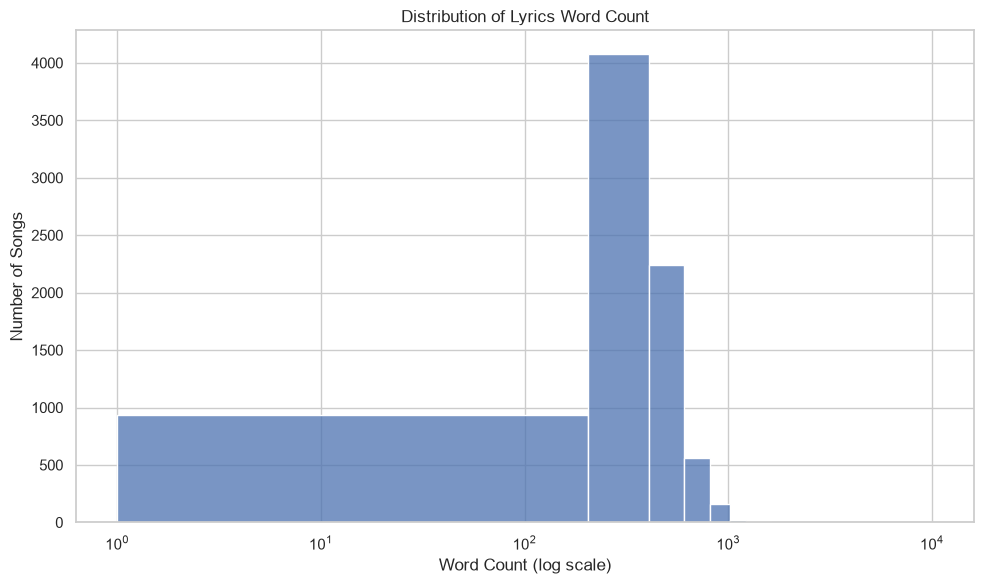

In [11]:
# 11. Distribution of Lyric Length

plt.figure(figsize=(10, 6))

sns.histplot(
    data=lyrics_df[lyrics_df["lyrics_word_count"] > 0],
    x="lyrics_word_count",
    bins=50
)

plt.xscale("log")
plt.title("Distribution of Lyrics Word Count")
plt.xlabel("Word Count (log scale)")
plt.ylabel("Number of Songs")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "lyrics_word_count_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Why use a log scale?

Because a small number of songs may have extremely long lyrics.

Without log scaling, those extreme observations can compress the majority of songs into a small part of the chart.


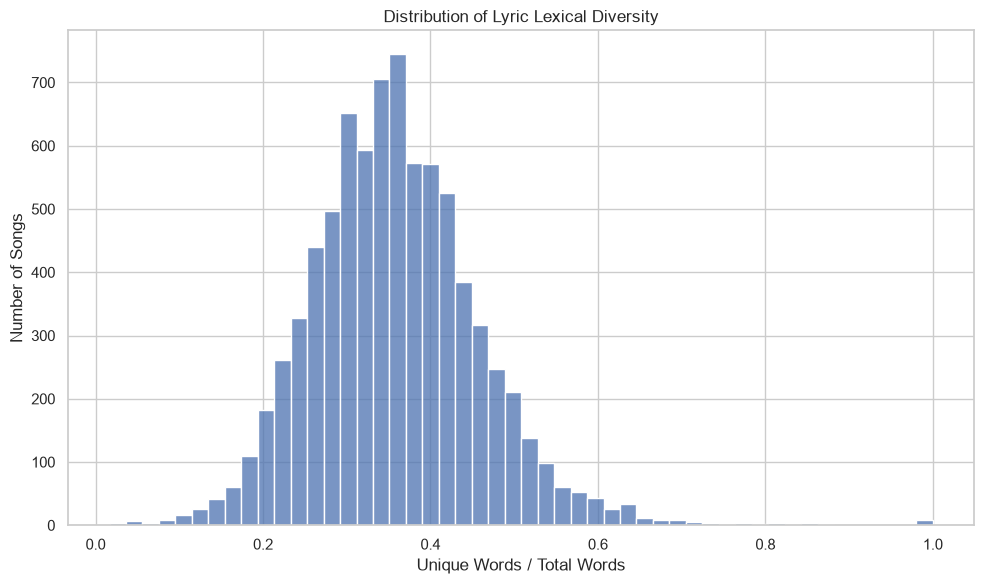

In [12]:
# 12. Distribution of Lexical Diversity 

plt.figure(figsize=(10, 6))

sns.histplot(
    data=lyrics_df[
        lyrics_df["lexical_diversity"].notna()
    ],
    x="lexical_diversity",
    bins=50
)

plt.title("Distribution of Lyric Lexical Diversity")
plt.xlabel("Unique Words / Total Words")
plt.ylabel("Number of Songs")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "lexical_diversity_distribution.png",
    dpi=300,
    bbox_inches = "tight"
)

plt.show()

This helps us understand the vocabulary variety across songs.

A song with: 100 total words 80 unique words

has: 0.80 lexical diversity

while: 100 total words 20 unique words has 0.20 lexical diversity

The second song contains considerable more repetition.

13. Stopword Removal - For frequency analysis, common words such as:

the, a, and, I, you, to , of  usually provide limited thematic information.

In [13]:
# Recreate Stopwords

import nltk 

nltk.download("stopwords", quiet=True)

from nltk.corpus import stopwords 

STOPWORDS = set(stopwords.words("english"))

STOPWORDS.update([
    "yeah",
    "oh",
    "ooh",
    "woah",
    "uh",
    "na",
    "la"
])

print("Number of stopwords:", len(STOPWORDS))


Number of stopwords: 205


Stopwords are very common words that often carry limited thematic information.

Examples: the,a,an,and,is,to,of,in
For word-frequency analysis, removing them helps expose more meaningful vocabulary.

In [14]:
# Tokenization Function

def tokenize_lyrics(text):
    """
    Convert lyrics into normalized word tokens.

    Steps:
    1. Convert to lowercase
    2. Extract alphabetic words
    3. Remove English stopwords
    4. Remove very short words
    """

    if pd.isna(text):
        return []

    text = str(text).lower()

    tokens = re.findall(
        r"\b[a-zA-Z']+\b",
        text
    )

    tokens = [
        token
        for token in tokens 
        if token not in STOPWORDS
        and len(token) > 1
    ]

    return tokens

In [15]:
# Recreate the tokens

lyrics_df["tokens"] = (
    lyrics_df["lyrics_nlp"]
    .fillna("")
    .apply(tokenize_lyrics)
)

lyrics_df["meaningful_word_count"] = (
    lyrics_df["tokens"].apply(len)
)

print(
    "songs with at least one meaningful token:",
    lyrics_df["tokens"].apply(len).gt(0).sum()
)

print(
    "Total meaningful tokens:",
    lyrics_df["tokens"].apply(len).sum()
)

songs with at least one meaningful token: 8021
Total meaningful tokens: 1707517


In [16]:
# Check a few tokenized lyrics

sample_tokens = (
    lyrics_df.loc[
        lyrics_df["tokens"].apply(len).gt(0),
        ["artist name", "song name", "tokens"]
    ]
    .head(5)
)

display(sample_tokens)

,artist name,song name,tokens
0,The Weeknd,Blinding Lights,"[tryna, call, long, enough, maybe, show, love,..."
1,Ed Sheeran,Shape of You,"[club, best, place, find, lover, bar, go, frie..."
2,Harry Styles,As It Was,"[harry, styles, come, harry, wanna, say, goodn..."
3,The Neighbourhood,Sweater Weather,"[man, want, world, hands, hate, beach, stand, ..."
4,Lewis Capaldi,Someone You Loved,"[going, time, fear, there's, one, save, nothin..."


Tokenization converts "I love music and I love you"
into individual units such as:
["love", "music", "love"] after stopword removal

These tokens will be used to frequency analysis.

In [17]:
# 15. Test Tokenization

sample_text = lyrics_df.loc[
    lyrics_df["lyrics_nlp"].ne(""),
    "lyrics_nlp"
].iloc[0]

print(
    tokenize_lyrics(sample_text)[:30]
)


['tryna', 'call', 'long', 'enough', 'maybe', 'show', 'love', 'maybe', 'going', 'withdrawals', 'even', 'much', 'turn', 'touch', 'baby', 'look', 'around', 'sin', "city's", 'cold', 'empty', "one's", 'around', 'judge', "can't", 'see', 'clearly', 'gone', 'said', 'blinded']


Always test a text-processing function before applying it to 8,000+ records.
This lets you catch issues early

In [18]:
# 16. Create Token Column

lyrics_df["tokens"] = (
    lyrics_df["lyrics_nlp"]
    .apply(tokenize_lyrics)
)

lyrics_df["meaningful_word_count"] = (
    lyrics_df["tokens"].str.len()
)

display(
    lyrics_df[
        [
            "artist name",
            "song name",
            "meaningful_word_count"
        ]
    ].head()
)

,artist name,song name,meaningful_word_count
0,The Weeknd,Blinding Lights,99
1,Ed Sheeran,Shape of You,282
2,Harry Styles,As It Was,82
3,The Neighbourhood,Sweater Weather,155
4,Lewis Capaldi,Someone You Loved,132


We now have:

lyrics_nlp
|
tokens
|
meaningful_word_count 

This gives us another potentially useful NLP feature.

In [19]:
# Most Frequent Words

from collections import Counter

all_tokens = []

for tokens in lyrics_df["tokens"]:
    all_tokens.extend(tokens)

word_counts = Counter(all_tokens)

top_words = pd.DataFrame(
    word_counts.most_common(50),
    columns=[
        "word",
        "frequency"
    ]
)

display(
    top_words.head(30)
)

,word,frequency
0,like,22461
1,que,18745
2,know,17903
3,got,14622
4,love,14277
5,get,12064
6,baby,10211
7,go,9763
8,te,9593
9,de,9424


In [20]:
# Save

top_words.to_csv(
    TABLE_DIR / "top_lyrics_words.csv",
    index=False
)

This tells us which words occur most often throughout the entire lyrics corpus.

This is a corpus-level descriptive analysis.

It does not mean that frequent words necesarily cause success.

In [21]:
# Diagnose the problem 

print("Number of songs:", len(lyrics_df))

print("\nLyrics available:")
print(lyrics_df["lyrics_available"].value_counts())

print("\nNon-empty NLP lyrics:")
print(
    (lyrics_df["lyrics_nlp"].str.len() > 0).sum()
)

print("\nNumber of token lists:")
print(len(lyrics_df["tokens"]))

print("\nNon-empty token lists:")
print(
    lyrics_df["tokens"].apply(len).gt(0).sum()
)

print("\nTotal tokens:")
print(
    lyrics_df["tokens"].apply(len).sum()
)

print("\nWord counts:")
print(
    len(word_counts)
)

print("\nTop words:")
display(top_words.head(20))

Number of songs: 8058

Lyrics available:
lyrics_available
True     8043
False      15
Name: count, dtype: int64

Non-empty NLP lyrics:
8025

Number of token lists:
8058

Non-empty token lists:
8021

Total tokens:
1707517

Word counts:
65450

Top words:


,word,frequency
0,like,22461
1,que,18745
2,know,17903
3,got,14622
4,love,14277
5,get,12064
6,baby,10211
7,go,9763
8,te,9593
9,de,9424


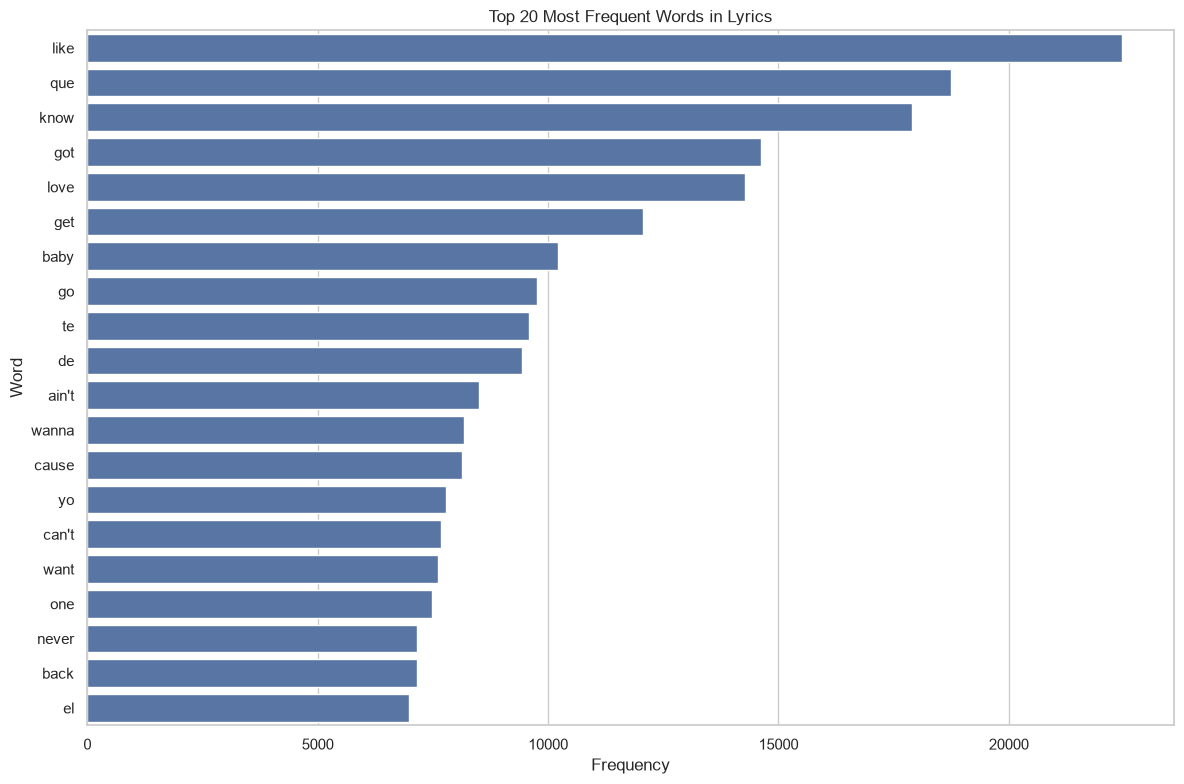

In [22]:
# 18. Top 20 Word Visualization

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_words.head(20),
    y="word",
    x="frequency"
)

plt.title(
    "Top 20 Most Frequent Words in Lyrics"
)

plt.xlabel("Frequency")
plt.ylabel("Word")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "top_20_lyrics_words.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


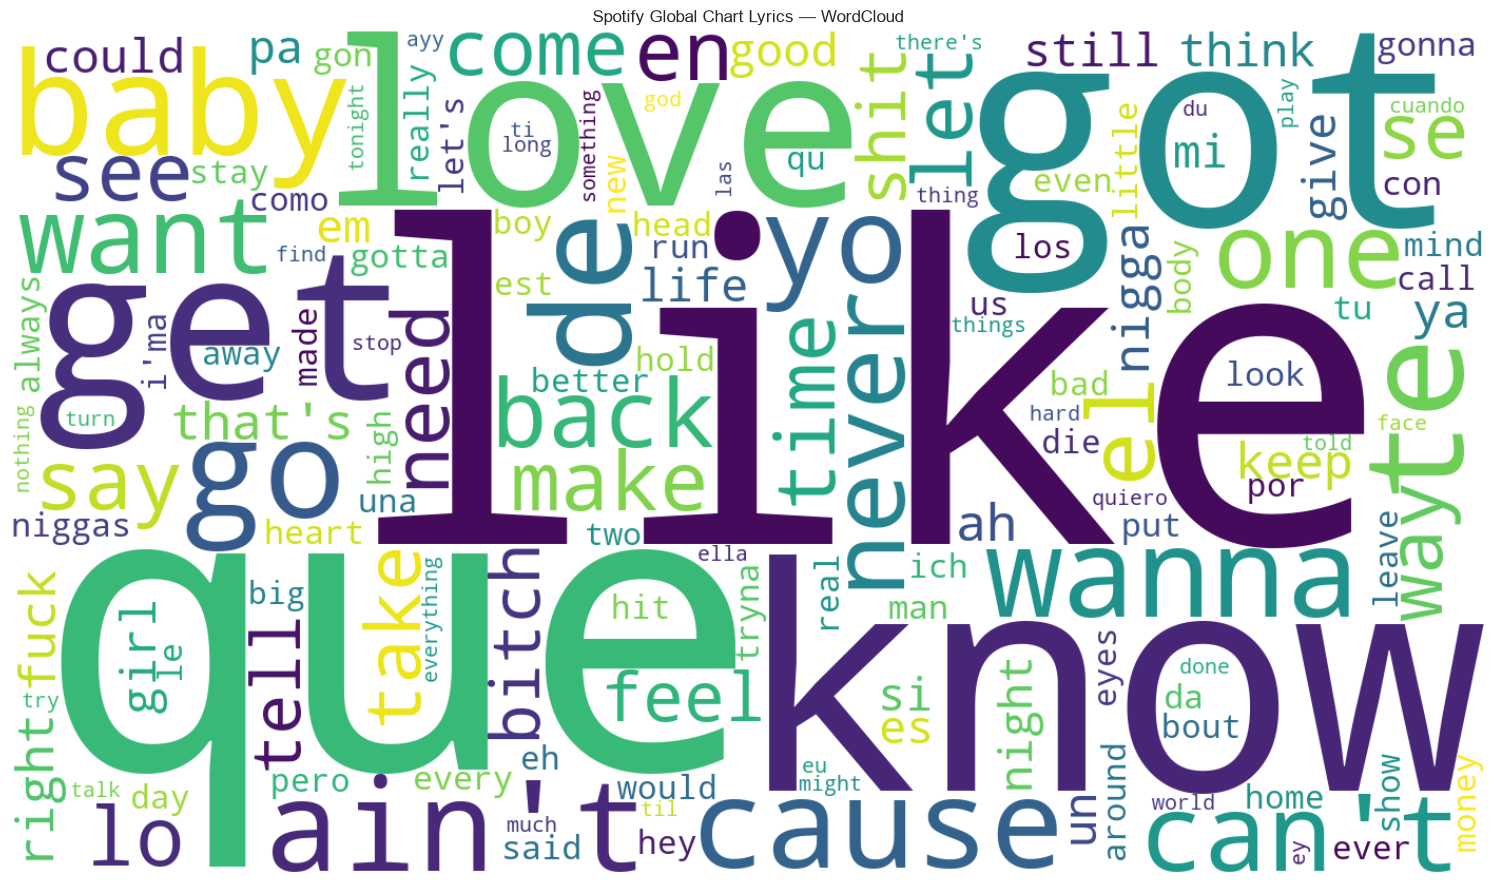

In [23]:
# 19. WordCloud 

wordcloud = WordCloud(
    width=1400,
    height=800,
    background_color="white",
    stopwords=STOPWORDS,
    max_words=150
).generate_from_frequencies(
    word_counts
)

plt.figure(figsize=(16, 9))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title(
    "Spotify Global Chart Lyrics — WordCloud"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "lyrics_wordcloud.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 20 Bigram Analysis

A bigram consists of two consecutive words

For example I Love music tonight

contains I love, love music, music tonight

After stopword filtering, meaningful phrases may emerge.

In [24]:
bigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2,2),
    min_df=5
)

bigram_matrix = (
    bigram_vectorizer.fit_transform(
        lyrics_df.loc[
            lyrics_df["lyrics_nlp"].ne(""),
            "lyrics_nlp"
        ]
    )
)

bigram_counts = np.asarray(
    bigram_matrix.sum(axis=0)
).ravel()

bigrams = pd.DataFrame({
    "bigram":
        bigram_vectorizer.get_feature_names_out(),
    "frequency":
        bigram_counts
}).sort_values(
    "frequency",
    ascending=False
)

display(
    bigrams.head(30)
)

,bigram,frequency
14186,oh oh,8689
22231,yeah yeah,4039
9619,la la,3798
13285,na na,3356
14374,ooh ooh,2578
40,ah ah,2480
4040,don know,2381
11515,lo que,1814
4156,don wanna,1773
11968,love love,1515


In [25]:
# Save

bigrams.to_csv(
    TABLE_DIR / "top_lyrics_bigrams.csv",
    index=False
)

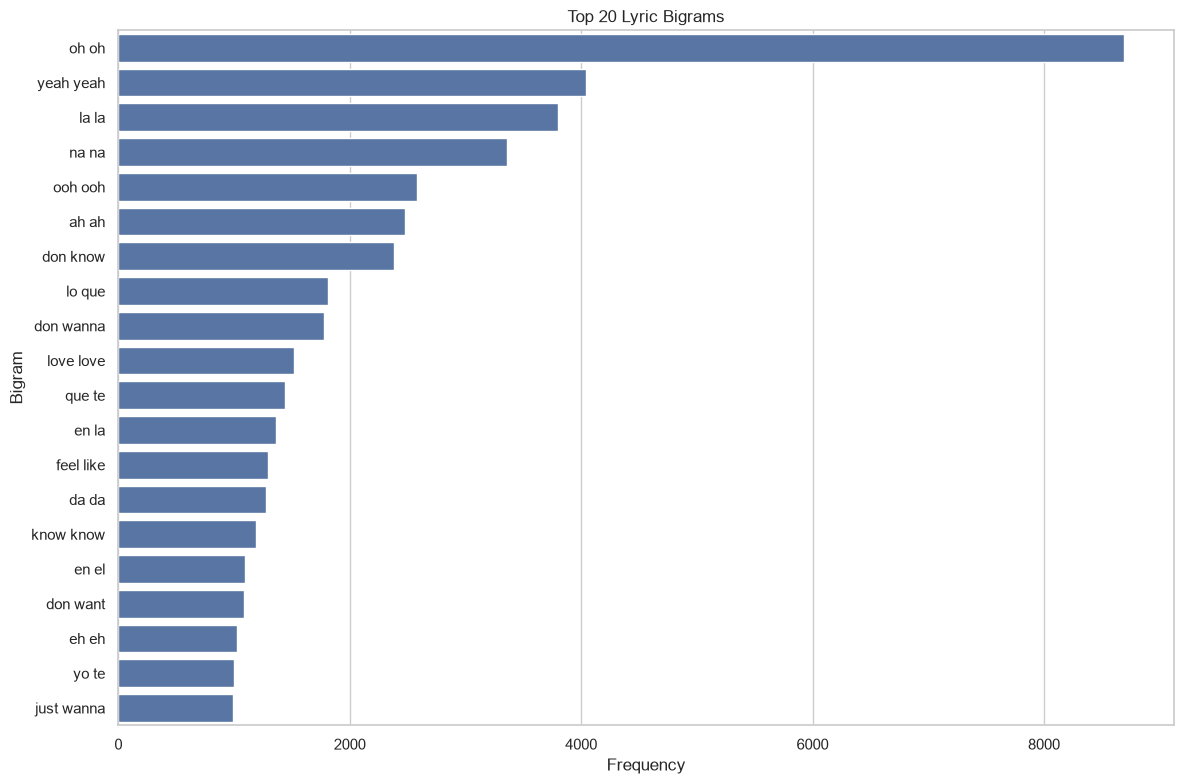

In [26]:
# 21. Bigram Visualization

plt.figure(figsize=(12, 8))

sns.barplot(
    data=bigrams.head(20),
    y="bigram",
    x="frequency"
)

plt.title(
    "Top 20 Lyric Bigrams"
)

plt.xlabel("Frequency")
plt.ylabel("Bigram")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "top_20_lyrics_bigrams.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [27]:
# 22. Trigram Analysis

# A trigram contains three consecutive words 

# This can capture more specific phrases than individual words or bigrams


trigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(3, 3),
    min_df=5
)

trigram_matrix = (
    trigram_vectorizer.fit_transform(
        lyrics_df.loc[
            lyrics_df["lyrics_nlp"].ne(""),
            "lyrics_nlp"
        ]
    )
)

trigram_counts = np.asarray(
    trigram_matrix.sum(axis=0)
).ravel()

trigrams = pd.DataFrame({
    "trigram":
        trigram_vectorizer.get_feature_names_out(),
    "frequency":
        trigram_counts
}).sort_values(
    "frequency",
    ascending=False
)

display(
    trigrams.head(30)
)

,trigram,frequency
2031,oh oh oh,5994
1401,la la la,3137
1887,na na na,2645
3260,yeah yeah yeah,2131
5,ah ah ah,1845
2106,ooh ooh ooh,1833
362,da da da,960
1739,love love love,778
696,eh eh eh,536
1336,know know know,519


In [28]:
# 23. Sentiment Analysis

# Now we examine the emotional polarity of lyrics

def sentiment_features(text):

    if not text:
        return pd.Series({
            "sentiment_polarity": np.nan,
            "sentiment_subjectivity": np.nan 
        })

    blob = TextBlob(text)

    return pd.Series({
        "sentiment_polarity":
            blob.sentiment.polarity,

        "sentiment_subjectivity":
            blob.sentiment.subjectivity
    })

In [29]:
# Apply it:

sentiment_df = (
    lyrics_df["lyrics_nlp"]
    .apply(sentiment_features)
)

lyrics_df = pd.concat(
    [
        lyrics_df,
        sentiment_df
    ],
    axis=1
)

display(
    lyrics_df[
        [
            "artist name",
            "song name",
            "sentiment_polarity",
            "sentiment_subjectivity"
        ]
    ].head()
)

,artist name,song name,sentiment_polarity,sentiment_subjectivity
0,The Weeknd,Blinding Lights,0.037500,0.597222
1,Ed Sheeran,Shape of You,0.299260,0.493270
2,Harry Styles,As It Was,0.078571,0.250595
3,The Neighbourhood,Sweater Weather,-0.100366,0.656995
4,Lewis Capaldi,Someone You Loved,0.267677,0.541414


# 24. Understand Sentiment Scores

Polarity 
Approximately 
-1 - Negative
0 - Neutral
1 - Positive

Subjectivity 
Approximately
0 - Objective
1 - Subjective 

Important limitation
TextBlob is a relatively simple lexicon/rule-based approach.

It may not correctly understand:
1) sarcasm
2) slang
3) cultural references
4) irony
5) metaphors
6) context
7) multilingual lyrics

Therefore, use the results as descriptive NLP features, not as absolute emotional truth. 


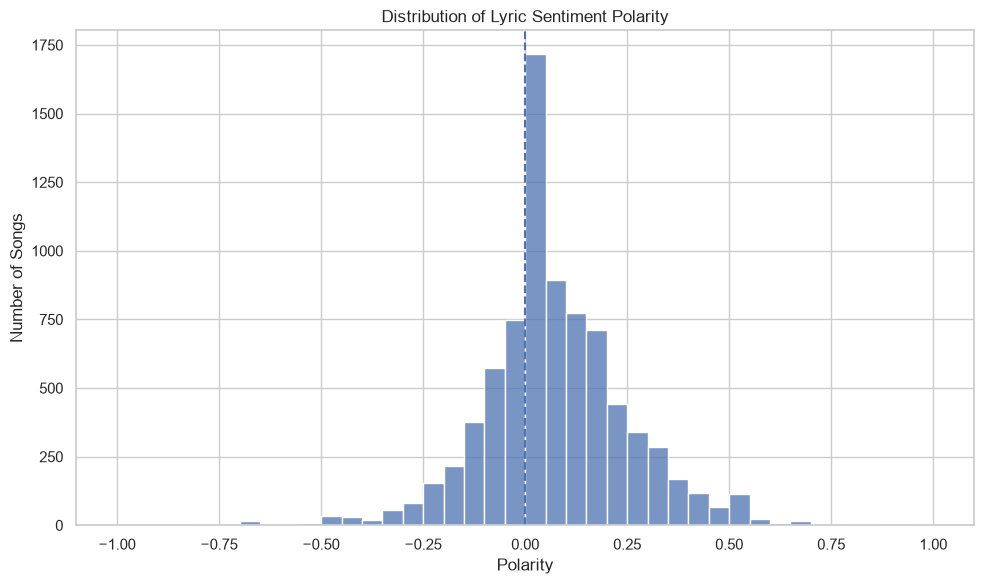

In [30]:
# 25. Sentiment Distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=lyrics_df,
    x="sentiment_polarity",
    bins=40
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title(
    "Distribution of Lyric Sentiment Polarity"
)

plt.xlabel(
    "Polarity"
)

plt.ylabel(
    "Number of Songs"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "sentiment_polarity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
# 26 Sentiment Categories

def classify_sentiment(score):

    if pd.isna(score):
        return "Unknown"

    elif score > 0.05:
        return "Positive"

    elif score > -0.05:
        return "Negative"

    else:
        return "Neutral"

lyrics_df["sentiment_category"] = (
    lyrics_df["sentiment_polarity"]
    .apply(classify_sentiment)
)

display(
    lyrics_df[
        "sentiment_category"
    ].value_counts()
)

sentiment_category
Positive    3973
Negative    2469
Neutral     1583
Unknown       33
Name: count, dtype: int64

We convert a continuous score into three descriptive categories

Positive, Neutral & Negative 

The threshold is intentionally simple and should not be interpreted as a clinical or psychological classification.

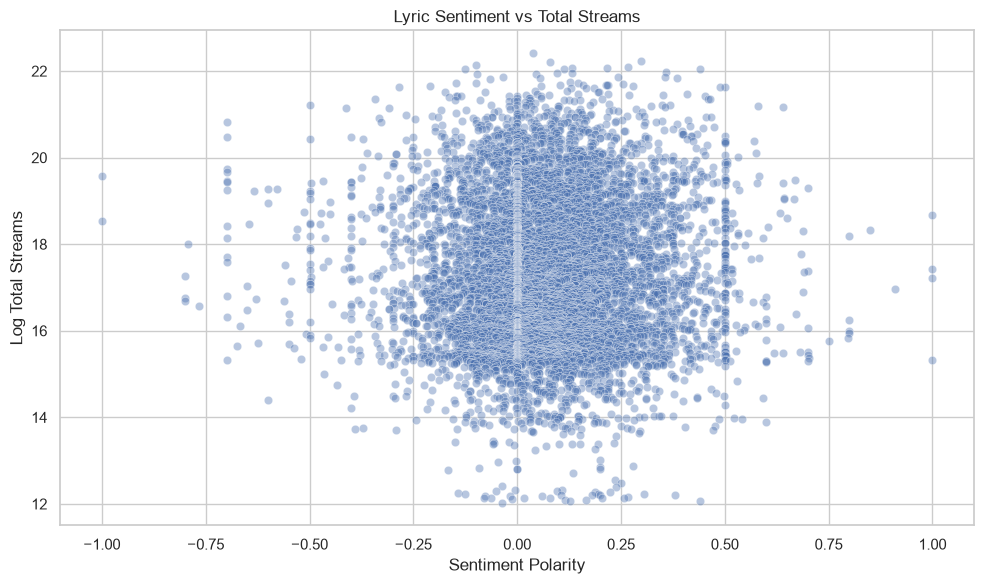

In [32]:
# 27. Sentiment vs Total Streams

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=lyrics_df[
        lyrics_df["lyrics_available"]
    ],
    x="sentiment_polarity",
    y="log_total",
    alpha=0.4
)

plt.title(
    "Lyric Sentiment vs Total Streams"
)

plt.xlabel(
    "Sentiment Polarity"
)

plt.ylabel(
    "Log Total Streams"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "sentiment_vs_total_streams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Why log_total ?

The total distribution is highly right_skewed 

Using: np.log(total)

reduces the influence of extreme values and makes the relationship easier to visualize


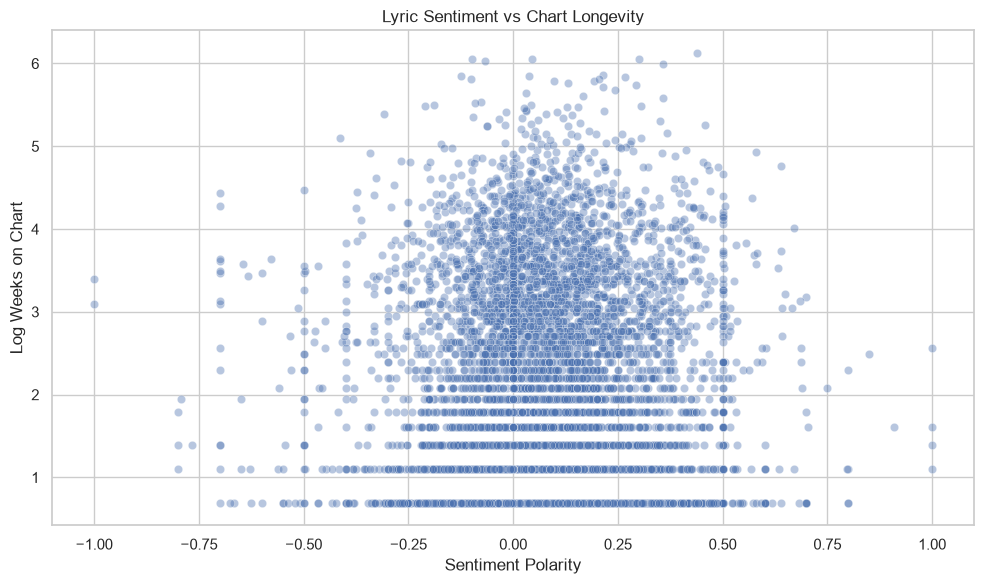

In [33]:
# 28. Sentiment vs Chart Longevity

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=lyrics_df[
        lyrics_df["lyrics_available"]
    ],
    x="sentiment_polarity",
    y="log_wks",
    alpha=0.4
)


plt.title(
    "Lyric Sentiment vs Chart Longevity"
)

plt.xlabel(
    "Sentiment Polarity"
)

plt.ylabel(
    "Log Weeks on Chart"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "sentiment_vs_chart_longevity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

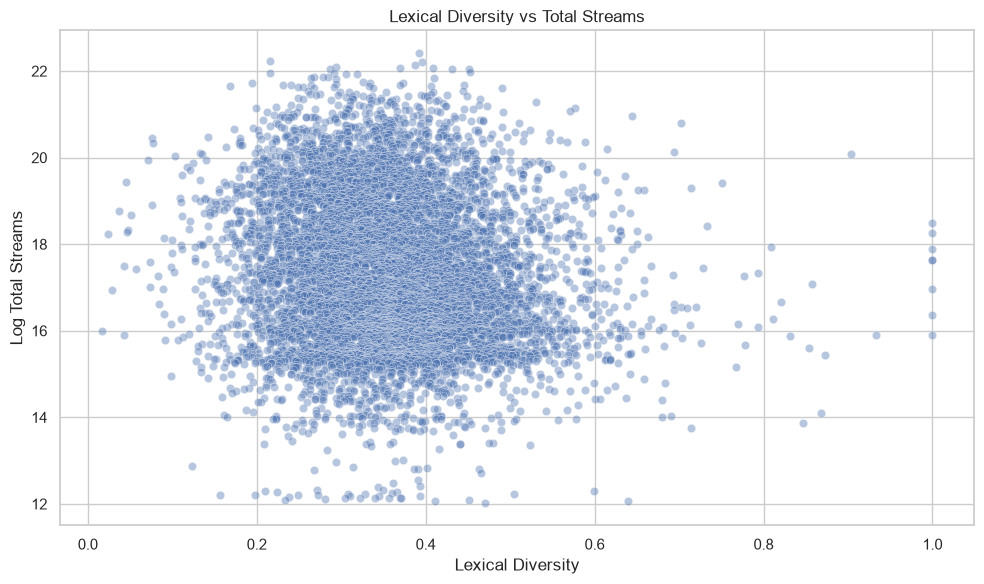

In [34]:
# 29. Lexical Diversity vs Total Streams

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=lyrics_df[
        lyrics_df["lyrics_available"]
    ],
    x="lexical_diversity",
    y="log_total",
    alpha=0.4
)

plt.title(
    "Lexical Diversity vs Total Streams"
)

plt.xlabel(
    "Lexical Diversity"
)

plt.ylabel(
    "Log Total Streams"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "lexical_diversity_vs_streams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

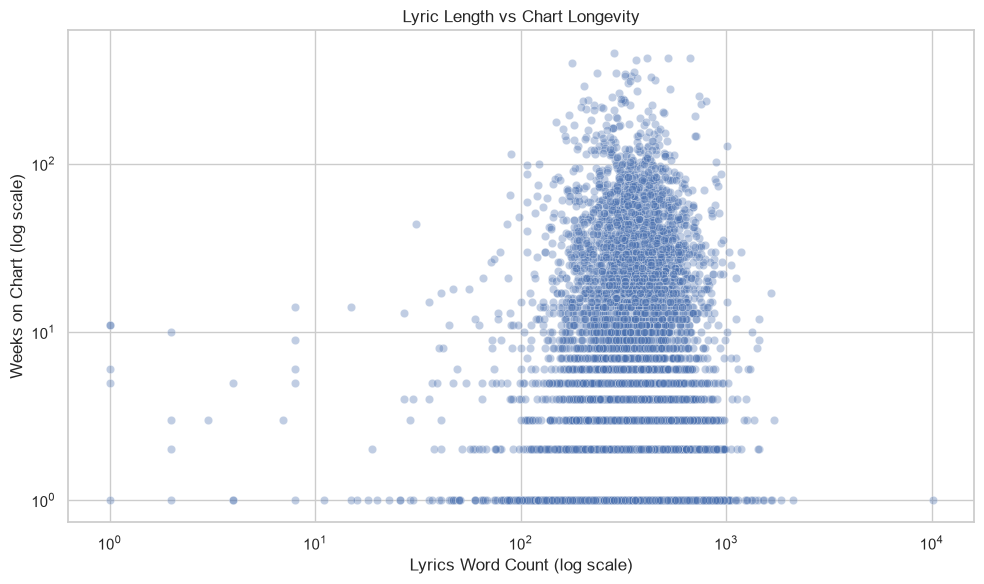

In [35]:
# 30 Lyrics length vs Longevity

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=lyrics_df[
        lyrics_df["lyrics_available"]
    ],
    x="lyrics_word_count",
    y="wks",
    alpha=0.35
)

plt.xscale("log")
plt.yscale("log")

plt.title(
    "Lyric Length vs Chart Longevity"
)

plt.xlabel(
    "Lyrics Word Count (log scale)"
)

plt.ylabel(
    "Weeks on Chart (log scale)"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / 
    "lyric_length_vs_longevity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
# 31 . Top-10 vs Non-Top-10 Lyrics

top10_lyric_summary = (
    lyrics_df[
        lyrics_df["lyrics_available"]
    ]
    .groupby("top10_reached")
    .agg(
        songs=("song name", "count"),
        median_words = (
            "lyrics_word_count",
            "median"
        ),
        median_unique_words=(
            "lyrics_unique_word_count",
            "median"
        ),
        median_lexical_diversity=(
            "lexical_diversity",
            "median"
        ),
        median_sentiment=(
            "sentiment_polarity",
            "median"
        ),
        median_subjectivity=(
            "sentiment_subjectivity",
            "median"
        ),
        median_weeks = (
            "wks",
            "median"
        ),
        median_total_streams=(
            "total",
            "median"
        )
    )
)
display(top10_lyric_summary)

,songs,median_words,median_unique_words,median_lexical_diversity,median_sentiment,median_subjectivity,median_weeks,median_total_streams
top10_reached,,,,,,,,
0,7233,355.0,117.0,0.354621,0.046624,0.497265,3.0,21928725.0
1,810,369.5,118.0,0.342294,0.062993,0.513095,44.0,475375574.5


This is a useful business-style comparison.

Do songs that reached the Top 10 have different lyrical characteristics from songs that did not?

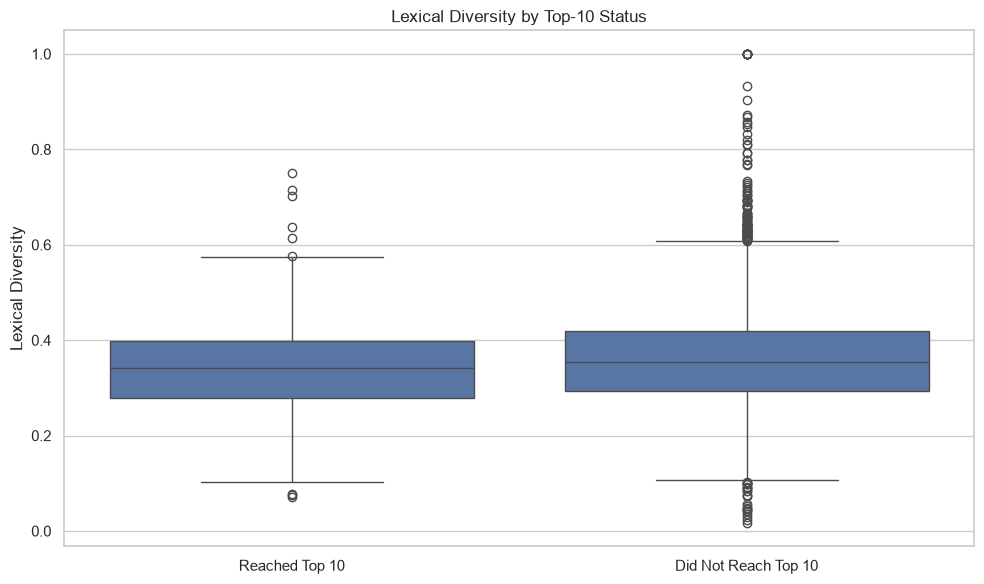

In [37]:
# 32. Lexical Diversity by Top-10 Status

plot_df = (
    lyrics_df[
        lyrics_df["lyrics_available"]
    ]
    .copy()
)

plot_df["Top10_Status"] = np.where(
    plot_df["top10_reached"] == 1,
    "Reached Top 10",
    "Did Not Reach Top 10"
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=plot_df,
    x="Top10_Status",
    y="lexical_diversity"
)

plt.title(
    "Lexical Diversity by Top-10 Status"
)

plt.xlabel("")
plt.ylabel(
    "Lexical Diversity"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / 
    "lexical_diversity_top10_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 33. Spearman Correlation

The performance variables are strongly skewed.

Spearman correlation measures whether two variables have a monotonic relationship, without requiring a normal distribution.

In [38]:
nlp_performance_cols = [
    "lyrics_word_count",
    "lyrics_unique_word_count",
    "lexical_diversity",
    "avg_word_length",
    "sentiment_polarity",
    "sentiment_subjectivity",
    "wks",
    "t10",
    "pk",
    "PkStreams",
    "total"
]

nlp_corr = (
    lyrics_df[
        nlp_performance_cols
    ]
    .corr(method="spearman")
)

display(nlp_corr)

,lyrics_word_count,lyrics_unique_word_count,lexical_diversity,avg_word_length,sentiment_polarity,sentiment_subjectivity,wks,t10,pk,PkStreams,total
lyrics_word_count,1.000000,0.814873,-0.127077,-0.047793,-0.104249,0.029712,-0.001930,0.034326,-0.050444,-0.026091,-0.013742
lyrics_unique_word_count,0.814873,1.000000,0.407711,0.147319,-0.146953,-0.003628,-0.111706,0.002207,-0.031924,0.039232,-0.070182
lexical_diversity,-0.127077,0.407711,1.000000,0.351203,-0.092239,-0.055115,-0.207227,-0.061162,0.033534,0.095399,-0.119508
avg_word_length,-0.047793,0.147319,0.351203,1.000000,-0.010597,0.026479,-0.163577,-0.041499,0.054661,-0.036150,-0.147845
sentiment_polarity,-0.104249,-0.146953,-0.092239,-0.010597,1.000000,0.154516,0.031378,0.013677,-0.024094,-0.008469,0.012647
sentiment_subjectivity,0.029712,-0.003628,-0.055115,0.026479,0.154516,1.000000,0.023647,0.042456,-0.061618,-0.002527,0.005738
wks,-0.001930,-0.111706,-0.207227,-0.163577,0.031378,0.023647,1.000000,0.419129,-0.650153,0.417417,0.917277
t10,0.034326,0.002207,-0.061162,-0.041499,0.013677,0.042456,0.419129,1.000000,-0.521167,0.451907,0.453669
pk,-0.050444,-0.031924,0.033534,0.054661,-0.024094,-0.061618,-0.650153,-0.521167,1.000000,-0.772369,-0.768389
PkStreams,-0.026091,0.039232,0.095399,-0.036150,-0.008469,-0.002527,0.417417,0.451907,-0.772369,1.000000,0.706458


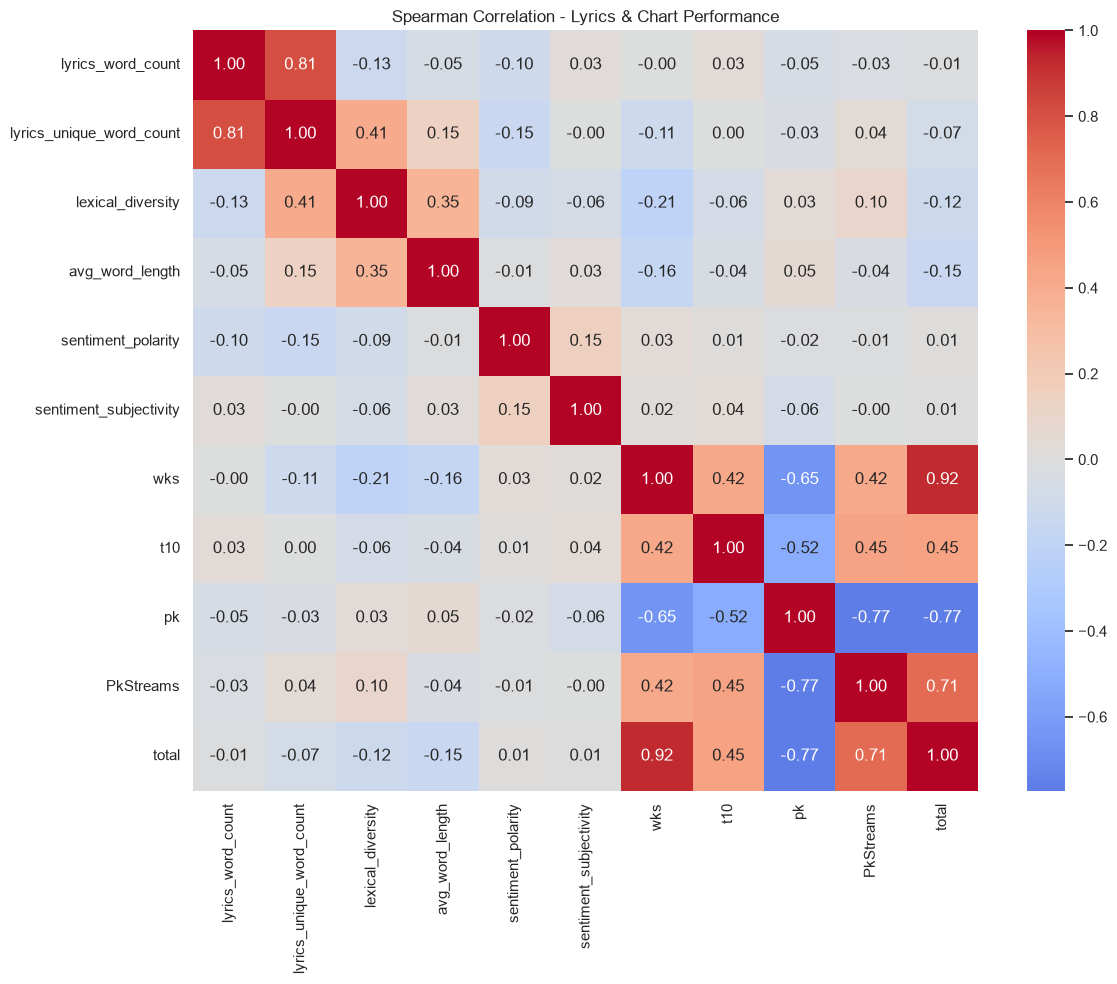

In [39]:
# 34. NLP Correlation Heatmap 

plt.figure(figsize=(12, 10))

sns.heatmap(
    nlp_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Spearman Correlation - Lyrics & Chart Performance"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "lyrics_chart_performance_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The heatmap allows us to quickly identify relationships.

For example
+0.70 -> strong positive association
0.00 -> little monotonic association
-0.70 -> strong negative association

Correlation does not establish causation

# 35. TF-IDF 
Now we move from simple word counts to an important NLP presentation.

what is TF-IDF ?

TF- IDF stands for:

Term frequency - Inverse Document Frequency

It gives more weight to words that are important to a particular document but less common across the entie corpus.

For example: If the word love appears in almost every song, it gets low discriminative weight.

A more unusual word appearing strongly in only a subset of songs can receive higher TF-IDF.

In [40]:
# 36. Create TF-IDF Matrix

tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=3,
    max_df=0.90,
    ngram_range=(1, 2),
    sublinear_tf=True
)

tfidf_matrix = (
    tfidf_vectorizer.fit_transform(
        lyrics_df["lyrics_nlp"]
    )
)

print(
    "TF-IDF matrix shape:",
    tfidf_matrix.shape
)

TF-IDF matrix shape: (8058, 5000)


Parameters:

Parameter                           Meaning

max_features=5000                   Keep up to 5,000 terms

min_df=3                            Ignore terms appearing in fewer than 3 songs

max_df=.90                          Ignore terms appearing in more than 90% songs

ngram_range(1,2)                    Unigrams + bigrams

sublinear_tf=True                   Dampens the effect of very frequent terms

The result is a sparse matrix:

Songs x NLP Features

In [41]:
# 37. Inspect TF-IDF Vocabulary 

tfidf_features = (
    tfidf_vectorizer
    .get_feature_names_out()
)

print(
    "Number of TF-IDF features:",
    len(tfidf_features)
)

print(
    tfidf_features[:50]
)

Number of TF-IDF features: 5000
['aa' 'ab' 'abajo' 'aber' 'abracadabra' 'ac' 'acabe' 'account' 'act'
 'act like' 'actin' 'actin like' 'acting' 'acting like' 'action'
 'actually' 'acuerdo' 'ad' 'ada' 'add' 'addicted' 'adentro' 'admit'
 'adore' 'advice' 'ae' 'afford' 'afraid' 'age' 'ago' 'agora' 'agree'
 'agua' 'ah' 'ah ah' 'ah ha' 'ah la' 'ah oh' 'ah ooh' 'ah yeah' 'ahead'
 'ahh' 'ahn' 'ahora' 'ahora que' 'ai' 'ai ai' 'aim' 'aime' 'ain']


In [42]:
# 38. Highest Average TF-IDF Terms

mean_tfidf = np.asarray(
    tfidf_matrix.mean(axis=0)
).ravel()

tfidf_terms = pd.DataFrame({
    "term": tfidf_features,
    "mean_tfidf": mean_tfidf
}).sort_values(
    "mean_tfidf",
    ascending=False
)

display(
    tfidf_terms.head(30)
)

,term,mean_tfidf
2350,like,0.032412
1036,don,0.031391
2146,know,0.030406
3011,oh,0.028870
2058,just,0.028286
4912,yeah,0.028122
2515,love,0.026865
1656,got,0.026107
2423,ll,0.022506
589,cause,0.021786


In [43]:
# Save

tfidf_terms.to_csv(
    TABLE_DIR / "top_tfidf_terms.csv",
    index=False
)

This gives us terms with relatively high average TF-IDF umportance across the corpus.

TF-IDF itself is more useful later for machine learning than simply looking at the top terms.

# 39. Topic Modeling 

Now we try to discover broad patterns in lyrical vocabulary.

We'll use:

Latent Dirichlet Allocation - LDA 

Concept - Imagine the songs are mixtures of topics:

Song A
Topic 1 - 70%
Topic 2 - 20%
Topic 3 - 10%

Another song might be:
Song B 
Topic 1 - 10%
Topic 2 - 80%
Topic 3 - 10%

LDA attempts to discover those topic distributions automatically.


In [44]:
# 40. Create Topic Matrix

topic_vectorizer = CountVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=5,
    max_df=0.90
)

topic_matrix = (
    topic_vectorizer.fit_transform(
        lyrics_df["lyrics_nlp"]
    )
)

print(
    "Topic matrix shape:",
    topic_matrix.shape
)

Topic matrix shape: (8058, 5000)


In [45]:
# 41. Train LDA 

N_TOPICS = 8 

lda_model = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=42,
    learning_method="batch",
    max_iter=20
)


lda_matrix = (
    lda_model.fit_transform(
        topic_matrix 
    )
)

print(
    "LDA matrix shape:",
    lda_matrix.shape
)

LDA matrix shape: (8058, 8)


We start with 8 topics.

This is not a statement that the dataset naturally contains exactly eight topics.

It is an analytical starting point

Later, you could compare 5,8,10,12 topics using topic coherence or interpretability.

In [46]:
# 42. Display Topic Words

topic_terms = (
    topic_vectorizer
    .get_feature_names_out()
)

def display_topics(
    model,
    feature_names,
    n_words=12
):

    topics = []

    for topic_idx, topic in enumerate(
        model.components_
    ):

        top_indices = (
            topic.argsort()[-n_words:][::-1]
        )

        words = [
            feature_names[i]
            for i in top_indices
        ]

        topics.append({
            "topic":
                topic_idx + 1,
            "top_words":
                ", ".join(words)
        })


    return pd.DataFrame(topics)

topics_df = display_topics(
    lda_model,
    topic_terms,
    n_words=15
)

display(topics_df)

,topic,top_words
0,1,"dance, run, like, christmas, party, girls, ll,..."
1,2,"love, baby, na, like, girl, need, let, got, co..."
2,3,"oh, yeah, ooh, ah, hey, whoa, woah, baby, want..."
3,4,"que, la, te, yo, el, en, lo, se, pa, si, mi, e..."
4,5,"don, know, just, like, ll, cause, time, ve, lo..."
5,6,"like, got, yeah, ain, bitch, don, shit, nigga,..."
6,7,"da, eu, na, que, vai, pra, ela, di, ba, non, s..."
7,8,"ich, du, und, die, nicht, ja, sie, wie, mir, a..."


The output might look conceptually like

Topic 1 -> love, heart, baby, night..
Topic 2 -> money, cash, work, city..
Topic 3 -> dance, party, tonight..

But do not force labels unless the words actually support the interpretation

In [48]:
# 43. Assign Dominant Topic 

lyrics_df["dominant_topic"] = (
    np.argmax(
        lda_matrix,
        axis=1
    ) + 1
)

lyrics_df["topic_probability"] = (
    np.max(
        lda_matrix,
        axis=1
    )
)

display(
    lyrics_df[
        [
            "artist name",
            "song name",
            "dominant_topic",
            "topic_probability"
        ]
    ].head(10)
)

,artist name,song name,dominant_topic,topic_probability
0,The Weeknd,Blinding Lights,5,0.679882
1,Ed Sheeran,Shape of You,2,0.811826
2,Harry Styles,As It Was,5,0.735412
3,The Neighbourhood,Sweater Weather,5,0.763539
4,Lewis Capaldi,Someone You Loved,5,0.991246
5,The Weeknd,Starboy,6,0.441119
6,Billie Eilish,BIRDS OF A FEATHER,5,0.890783
7,Lady Gaga,Die With A Smile,5,0.787488
8,Post Malone,Sunflower,5,0.449119
9,Ed Sheeran,Perfect,5,0.837272


For every song, LDA produces probabilities

Example
Topic 1 = 0.10
Topic 2 = 0.72
Topic 3 = 0.08
Topic 4 = 0.10

The dominant topic is Topic 2 and its probability is 0.72 

The probability tells us how strongly the song is associated with its dominant topic.

In [49]:
# 44. Topic Distribution

topic_distribution = (
    lyrics_df["dominant_topic"]
    .value_counts()
    .sort_index()
    .rename_axis("topic")
    .reset_index(name="songs")
)

topic_distribution["percentage"] = (
    topic_distribution["songs"]
    / topic_distribution["songs"].sum()
    * 100
)

display(topic_distribution)

,topic,songs,percentage
0,1,333,4.132539
1,2,498,6.180194
2,3,256,3.176967
3,4,1202,14.916853
4,5,3464,42.988335
5,6,1796,22.288409
6,7,264,3.276247
7,8,245,3.040457


In [50]:
# Save 

topic_distribution.to_csv(
    TABLE_DIR / "topic_distribution.csv",
    index=False
)

In [51]:
# 45. Topic vs Chart Performance

topic_performance = (
    lyrics_df
    .groupby("dominant_topic")
    .agg(
        songs=("song name", "count"),
        median_weeks=("wks", "median"),
        median_total_streams = (
            "total",
            "median"
    ),
    median_peak_position=(
        "pk",
        "median"
    ),
    top10_rate = (
        "top10_reached",
        "mean"
    ),
    median_lyric_words=(
            "lyrics_word_count",
            "median"
    ),
    median_sentiment=(
        "sentiment_polarity",
        "median"
    )

)

)

topic_performance["top10_rate"] *= 100

display(topic_performance)

,songs,median_weeks,median_total_streams,median_peak_position,top10_rate,median_lyric_words,median_sentiment
dominant_topic,,,,,,,
1,333,5.0,35255484.0,80.0,7.807808,231.0,0.154676
2,498,7.0,35684785.5,73.5,9.638554,330.5,0.152620
3,256,7.0,44667547.5,56.0,16.406250,295.5,0.082292
4,1202,10.0,71823636.0,72.0,8.569052,384.0,0.000000
5,3464,4.0,27401606.5,65.0,12.586605,318.0,0.085894
6,1796,3.0,18066280.5,74.0,8.518931,499.5,0.017990
7,264,4.0,27514286.5,126.0,0.757576,300.0,0.000000
8,245,2.0,8440805.0,129.0,0.000000,384.0,0.050000


How do songs dominated by different lyric topics differ in chart performance?

Again, this is descriptive.

We should not say: "Topic 4 causes songs to become successful."

Instead: "Songs assigned predominantely to Topic 4 had a higher median x in this dataset.

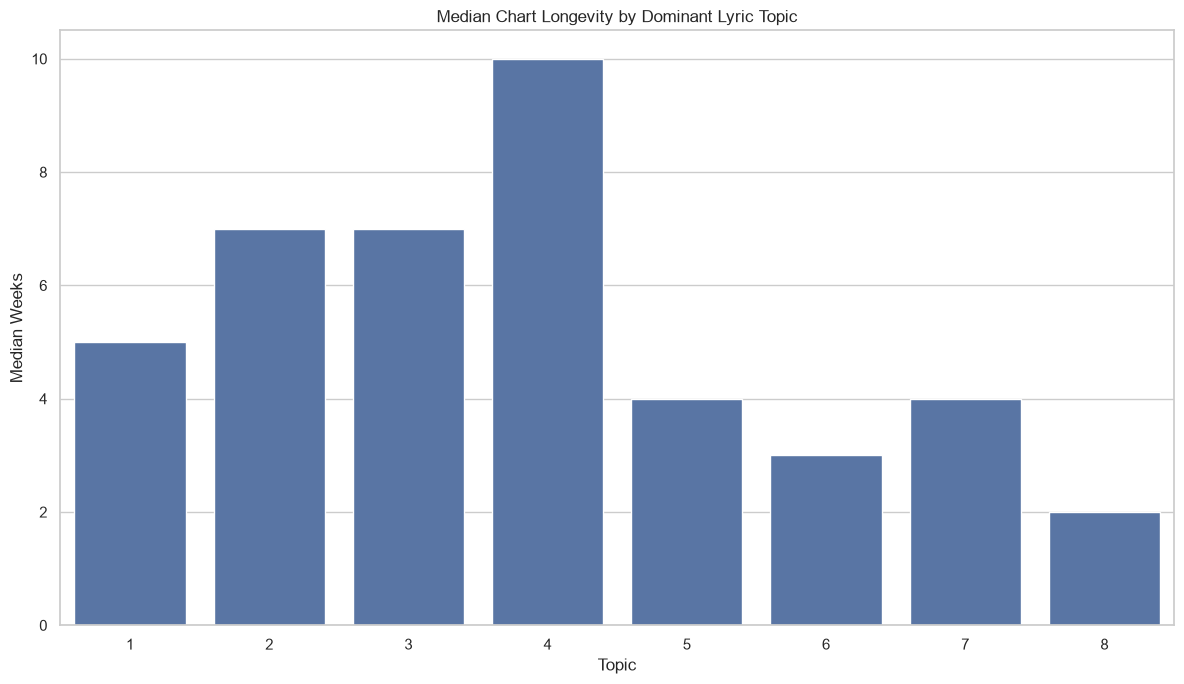

In [52]:
# 46. Topic vs Chart Longevity

plt.figure(figsize=(12, 7))

sns.barplot(
    data=topic_performance.reset_index(),
    x="dominant_topic",
    y="median_weeks"
)

plt.title(
    "Median Chart Longevity by Dominant Lyric Topic"
)

plt.xlabel("Topic")
plt.ylabel("Median Weeks")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "topic_vs_chart_longevity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
# 47. Example Songs for Each Topic 

topic_song_examples = (
    lyrics_df[
        lyrics_df["lyrics_available"]
    ]
    .sort_values(
        [
            "dominant_topic",
            "topic_probability"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "dominant_topic"
    )
    .head(5)
    [
        [
            "dominant_topic",
            "topic_probability",
            "artist name",
            "song name",
            "wks",
            "total"
        ]
    ]
)

display(topic_song_examples)

,dominant_topic,topic_probability,artist name,song name,wks,total
2669,1,0.995364,Foster The People,Pumped Up Kicks,22,71134422
1523,1,0.994596,Michael Jackson,Smooth Criminal,13,179189609
3085,1,0.994042,Various Artists,Happy,22,52334541
674,1,0.991815,Perry Como,It's Beginning to Look a Lot Like Christmas,39,430030498
2465,1,0.990378,Bing Crosby,Mele Kalikimaka,6,82413298
1045,2,0.997440,Peggy Gou,Nanana,22,277163329
2047,2,0.996055,One Direction,Steal My Girl,27,114774071
7919,2,0.996055,One Direction,Steal My Girl,1,1239262
3777,2,0.995554,Ariana Grande,true story,2,32695435
7342,2,0.994628,Kygo,Hot Stuff,1,4569978


This is especially useful for manually interpreting the topics.

Instead of relying only on the top words, we can inspect actual songs associated strongly with each topic.

In [55]:
# 48. Create Lyric Complexity Groups - We can divide songs based on lexical diversity.

valid_diversity = lyrics_df[
    lyrics_df["lexical_diversity"].notna()
].copy()

diversity_q1 = (
    valid_diversity[
        "lexical_diversity"
    ].quantile(0.25)
)

diversity_q3 = (
    valid_diversity[
        "lexical_diversity"
    ].quantile(0.75)
)

lyrics_df["lyric_complexity_group"] = np.select(
    [
        lyrics_df["lexical_diversity"] 
        <= diversity_q1,

        lyrics_df["lexical_diversity"]
        >= diversity_q3
    ],
    [
        "Lower lexical diversity",
        "Higher lexical diversity"
    ],
    default = "Middle lexical diversity"
)

display(
    lyrics_df[
        "lyric_complexity_group"
    ].value_counts()
)

lyric_complexity_group
Middle lexical diversity    4044
Lower lexical diversity     2007
Higher lexical diversity    2007
Name: count, dtype: int64

We use quartiles instead of arbitrary values

Bottom 25% -> Lower lexical diversity

Middle 50% -> Middle lexical diversity

Top 25% -> Higher lexical diversity

This is more defensible than saying somelthing like:

A song is complex if lexical diversity > 0.50

In [59]:
# 49. Complexity vs Chart Performance

complexity_performance = (
    lyrics_df
    .groupby(
        "lyric_complexity_group"
    )
    .agg(
        songs=("song name", "count"),
        median_words=(
            "lyrics_word_count",
            "median"
        ),
        median_weeks=(
            "wks",
            "median"
        ),
        median_total_streams=(
            "total",
            "median"
        ),
        top10_rate=(
            "top10_reached",
            "mean"
        ),
        median_peak_position=(
            "pk",
            "median"
        )
    )
)

complexity_performance[
    "top10_rate"
] *= 100

display(
    complexity_performance
)

,songs,median_words,median_weeks,median_total_streams,top10_rate,median_peak_position
lyric_complexity_group,,,,,,
Higher lexical diversity,2007,305.0,2.0,20034946.0,7.174888,75.0
Lower lexical diversity,2007,367.0,8.0,40511971.0,12.057798,72.0
Middle lexical diversity,4044,369.0,4.0,28096998.0,10.484669,73.0


In [61]:
# 50. Statistical Test - Lyrics vs Longevity

correlation_results = []

features_to_test = [
    "lyrics_word_count",
    "lyrics_unique_word_count",
    "lexical_diversity",
    "avg_word_length",
    "sentiment_polarity",
    "sentiment_subjectivity"
]

for feature in features_to_test:

    temp = lyrics_df[
        [
            feature,
            "wks"
        ]
    ].dropna()

    rho, p_value = spearmanr(
        temp[feature],
        temp["wks"]
    )

    correlation_results.append({
        "feature": feature,
        "spearman_rho": rho,
        "p_value": p_value,
        "n": len(temp)
    })

longevity_tests = pd.DataFrame(
    correlation_results
).sort_values(
    "spearman_rho",
    key=abs,
    ascending=False
)


display(longevity_tests)

,feature,spearman_rho,p_value,n
2,lexical_diversity,-0.207227,1.458523e-78,8025
3,avg_word_length,-0.163577,3.039282e-49,8025
1,lyrics_unique_word_count,-0.111706,8.527619e-24,8058
4,sentiment_polarity,0.031378,4.935962e-03,8025
5,sentiment_subjectivity,0.023647,3.415137e-02,8025
0,lyrics_word_count,-0.001930,8.624683e-01,8058


We calculate 
Spearman rho, p-value, sample size

The rho tells us the direction and strength of the monotonic association.

The p-value helps assess whether the observed association is statistically distinguishable from zero under the test assumptions.

However, statistical significance does not imply practical importance or causality.

In [62]:
# 51. Lyrics vs Total Streams

stream_results = []

for feature in features_to_test: 

    temp = lyrics_df[

        [
            feature,
            "total"
        ]
    ].dropna()

    rho, p_value = spearmanr(
        temp[feature],
        temp["total"]
    )

    stream_results.append({
        "feature": feature,
        "spearman_rho": rho,
        "p_value": p_value,
        "n": len(temp)
    })

stream_tests = pd.DataFrame(
    stream_results
).sort_values(
    "spearman_rho",
    key=abs,
    ascending=False
)

display(stream_tests)

,feature,spearman_rho,p_value,n
3,avg_word_length,-0.147845,1.882523e-40,8025
2,lexical_diversity,-0.119508,6.418057e-27,8025
1,lyrics_unique_word_count,-0.070182,2.848338e-10,8058
0,lyrics_word_count,-0.013742,2.173990e-01,8058
4,sentiment_polarity,0.012647,2.572838e-01,8025
5,sentiment_subjectivity,0.005738,6.073017e-01,8025


In [63]:
# Save

longevity_tests.to_csv(
    TABLE_DIR /
    "lyrics_longevity_spearman_tests.csv",
    index=False
)

stream_tests.to_csv(
    TABLE_DIR /
    "lyrics_streams_spearman_test.csv",
    index=False
)

In [64]:
# 52. Create NLP Feature Dataset 

nlp_features = lyrics_df[
    [
        "artist name",
        "song name",
        "lyrics_available",
        "lyrics_char_count",
        "lyrics_word_count",
        "lyrics_unique_word_count",
        "meaningful_word_count",
        "lexical_diversity",
        "avg_word_length",
        "sentiment_polarity",
        "sentiment_subjectivity",
        "sentiment_category",
        "dominant_topic",
        "topic_probability",
        "lyric_complexity_group"
    ]
].copy()

display(
    nlp_features.head()
)

,artist name,song name,lyrics_available,lyrics_char_count,lyrics_word_count,lyrics_unique_word_count,meaningful_word_count,lexical_diversity,avg_word_length,sentiment_polarity,sentiment_subjectivity,sentiment_category,dominant_topic,topic_probability,lyric_complexity_group
0,The Weeknd,Blinding Lights,True,1089,235,92,99,0.391489,3.638298,0.037500,0.597222,Negative,5,0.679882,Middle lexical diversity
1,Ed Sheeran,Shape of You,True,2940,669,144,282,0.215247,3.396114,0.299260,0.493270,Positive,2,0.811826,Lower lexical diversity
2,Harry Styles,As It Was,True,1115,245,97,82,0.395918,3.555102,0.078571,0.250595,Positive,5,0.735412,Middle lexical diversity
3,The Neighbourhood,Sweater Weather,True,1655,346,134,155,0.387283,3.786127,-0.100366,0.656995,Neutral,5,0.763539,Middle lexical diversity
4,Lewis Capaldi,Someone You Loved,True,1543,323,95,132,0.294118,3.780186,0.267677,0.541414,Positive,5,0.991246,Middle lexical diversity


This table contains the numerical and categorical NLP features that we may later use in ML.

For example
lyrics_word_count, lexical_diversity, sentiment_polarity, sentiment_subjectivity and dominant_topic 

These are much more useful to a machine-learning model than raw lyrics.

In [65]:
# 53. Save NLP Feature Dataset 

NLP_FEATURE_PATH = (
    PROJECT_ROOT 
    / "data"
    / "processed"
    / "spotify_lyrics_nlp_features.csv"
)

nlp_features.to_csv(
    NLP_FEATURE_PATH,
    index=False 
)

print(
    "NLP feature dataset saved to:"
)

print(NLP_FEATURE_PATH)

NLP feature dataset saved to:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_lyrics_nlp_features.csv


In [67]:
# 54. Create Lyrics + Performance Dataset

lyrics_performance = lyrics_df[
    [
        "artist name",
        "song name",
        "wks",
        "t10",
        "pk",
        "PkStreams",
        "total",
        "top10_reached",
        "lyrics_available",
        "lyrics_char_count",
        "lyrics_word_count",
        "lyrics_unique_word_count",
        "meaningful_word_count",
        "lexical_diversity",
        "avg_word_length",
        "sentiment_polarity",
        "sentiment_category",
        "dominant_topic",
        "topic_probability",
        "lyric_complexity_group"
    ]
].copy()

In [68]:
# Save

LYRICS_PERFORMANCE_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_lyrics_performance_analysis.csv"
)

lyrics_performance.to_csv(
    LYRICS_PERFORMANCE_PATH,
    index=False
)

print(
    "Saved to:",
    LYRICS_PERFORMANCE_PATH
)

Saved to: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_lyrics_performance_analysis.csv


This is an analysis-ready table containing both:
NLP features 
+
Chart Performance

In [69]:
# 55. Create NLP Summary

nlp_summary = {
    "total_songs":
        len(lyrics_df),

    "songs_with_lyrics":
        int(
            lyrics_df[
                "lyrics_available"
            ].sum()
        ),

    "songs_without_lyrics":
        int(
            (~lyrics_df[
                "lyrics_available"
            ]).sum()
        ),

    "mean_word_count":
        lyrics_df[
            "lyrics_word_count"
        ].mean(),

    "median_word_count":
        lyrics_df[
            "lyrics_word_count"
        ].median(),

    "mean_lexical_diversity":
        lyrics_df[
            "lexical_diversity"
        ].mean(),

    "median_lexical_diversity":
        lyrics_df[
            "lexical_diversity"
        ].median(),

    "mean_sentiment":
        lyrics_df[
            "sentiment_polarity"
        ].mean(),

    "median_sentiment":
        lyrics_df[
            "sentiment_polarity"
        ].median(),

    "number_of_topics":
        N_TOPICS, 

    "tfidf_features":
        len(tfidf_features)

}

nlp_summary_df = pd.DataFrame(
    [nlp_summary]
)

display(nlp_summary_df)

,total_songs,songs_with_lyrics,songs_without_lyrics,mean_word_count,median_word_count,mean_lexical_diversity,median_lexical_diversity,mean_sentiment,median_sentiment,number_of_topics,tfidf_features
0,8058,8043,15,384.011914,356.0,0.358164,0.353175,0.069336,0.048274,8,5000


In [70]:
# Save

nlp_summary_df.to_csv(
    TABLE_DIR /
    "lyrics_nlp_sumamry.csv",
    index=False
)

In [71]:
# 56. Final Validation

validation = {
    "Rows preserved":
        len(lyrics_df) == len(df),

    "Lyrics column exists":
        "lyrics" in lyrics_df.columns,

    "NLP text exists":
        "lyrics_nlp" in lyrics_df.columns,

    "Word count exists":
        "lyrics_word_count" in lyrics_df.columns,

    "Lexical diversity exists":
        "lexical_diversity" in lyrics_df.columns,

    "Sentiment exists":
        "sentiment_polarity" in lyrics_df.columns,

    "Topics assigned":
        "dominant_topic" in lyrics_df.columns,

    "NLP feature file exists":
        NLP_FEATURE_PATH.exists(),

    "Performance file exists":
        LYRICS_PERFORMANCE_PATH.exists()

}


display(
    pd.Series(
        validation,
        name="Validation"
    )
)

print(
    "\nAll checks passed",
    all(validation.values())
)

Rows preserved              True
Lyrics column exists        True
NLP text exists             True
Word count exists           True
Lexical diversity exists    True
Sentiment exists            True
Topics assigned             True
NLP feature file exists     True
Performance file exists     True
Name: Validation, dtype: bool


All checks passed True


In [73]:
# 57. Display all Generated Outputs

print("=" * 60)
print("FIGURES")
print("=" * 60)

for file in sorted(
    OUTPUT_DIR.glob("*")
):
    print(file.name)

print("\n" + "+" * 60)
print("TABLES")
print("=" * 60)

for file in sorted(
    TABLE_DIR.glob("*")
):

    print(file.name)


FIGURES
lexical_diversity_distribution.png
lexical_diversity_top10_status.png
lexical_diversity_vs_streams.png
lyric_length_vs_longevity.png
lyrics_chart_performance_correlation.png
lyrics_descriptive_statistics.csv
lyrics_longevity_spearman_tests.csv
lyrics_nlp_sumamry.csv
lyrics_streams_spearman_test.csv
lyrics_word_count_distribution.png
lyrics_wordcloud.png
sentiment_polarity_distribution.png
sentiment_vs_chart_longevity.png
sentiment_vs_total_streams.png
top_20_lyrics_bigrams.png
top_20_lyrics_words.png
top_lyrics_bigrams.csv
top_lyrics_words.csv
top_tfidf_terms.csv
topic_distribution.csv
topic_vs_chart_longevity.png

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
TABLES
lexical_diversity_distribution.png
lexical_diversity_top10_status.png
lexical_diversity_vs_streams.png
lyric_length_vs_longevity.png
lyrics_chart_performance_correlation.png
lyrics_descriptive_statistics.csv
lyrics_longevity_spearman_tests.csv
lyrics_nlp_sumamry.csv
lyrics_streams_spearman_test.csv
l

### 58. Final Notebook Conclusion

### Lyrics Coverage

The dataset contains lyrics for the large majority of charting songs, allowing NLP analysis across almost the complete song population.

### Lyric structure

Lyrics vary sustainability in:

- length
- vocabulary size
- lexical diversity
- average word length

These characteristics provide multiple ways to represent lyrical structure.

### Word Frequency

Frequent-word and n-gram analysis identifies recurring vacobulary and phrasing patterns across the Spotify Global Chart lyrics corpus.

### Sentiment

Sentiment analysis provides descriptive measures of polarity and subjectivity.

These scores should be interpreted cautiously because simple sentiment models may not understand sarcasm, slang, cultural references or complex lyrical context.

### Lexical Diversity

Lexical diversity measures the proportion of unique words relative to total words and provides a useful measure of vocabulary variety.

### Topic Modeling 

LDA identifies groups of words that frequently occur together across songs.

The resulting topics represent statistical patterns in the corpus, not manually verified semantic categories.

### Lyrics and Chart Performance

Relationships between lyrical characteristics and chart outcomes are descriptive associations.

They should not be interpreted as causal relationships.

### Machine Learning Features

The following NLP features have been created:

- lyrics character count
- lyrics word count
- unique word count
- meaningful word count
- lexical diversity
- average word length
- sentiment polarity
- sentiment subjectivity
- sentiment category
- dominant topic
- topic probability
- lyric complexity group

These features will be used in susequent feature engineering and machine-learning analyis.

### Next Step

The next notebook will combine:

Lyrics NLP
|
Chart Performance
|
Song-level characteristics

to create a structured feature set for segmentation and predictive modeling.



